# 02 · Patrones temporales de las incidencias registradas

**Entrada:** `datos/incidencias_limpias.csv` (de `01_calidad`).
**Regla de esta fase:** el periodo de prueba (5–8 jun) solo se cuenta. La serie diaria muestra conteos de todos los días
(contar filas está permitido); **todos los patrones que orientan decisiones** (turno, día × turno, hora, tipo, autocorrelación)
se calculan con la ventana estable **sin prueba**: 22 may – 4 jun (entrenamiento + validación, 14 días).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from _comun import *

configurar_estilo()
np.random.seed(SEMILLA)
pd.set_option("display.width", 160)

df = cargar_limpias()
df["fecha_dt"] = pd.to_datetime(df.fecha)
INI_EDA, FIN_EDA = INICIO_ESTABLE, PARTICION["valid"][1]
eda = df[(df.fecha >= INI_EDA) & (df.fecha <= FIN_EDA)].copy()
n_dias_eda = len(fechas_rango(INI_EDA, FIN_EDA))
print(f"Limpias: {len(df)} · ventana de análisis {INI_EDA} a {FIN_EDA} ({n_dias_eda} días): {len(eda)} registros")
metricas = {"ventana_eda": [INI_EDA, FIN_EDA], "registros_eda": int(len(eda)), "dias_eda": n_dias_eda}
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

Limpias: 2580 · ventana de análisis 2026-05-22 a 2026-06-04 (14 días): 1602 registros


## 1. Serie diaria por turno (conteo de todos los días)

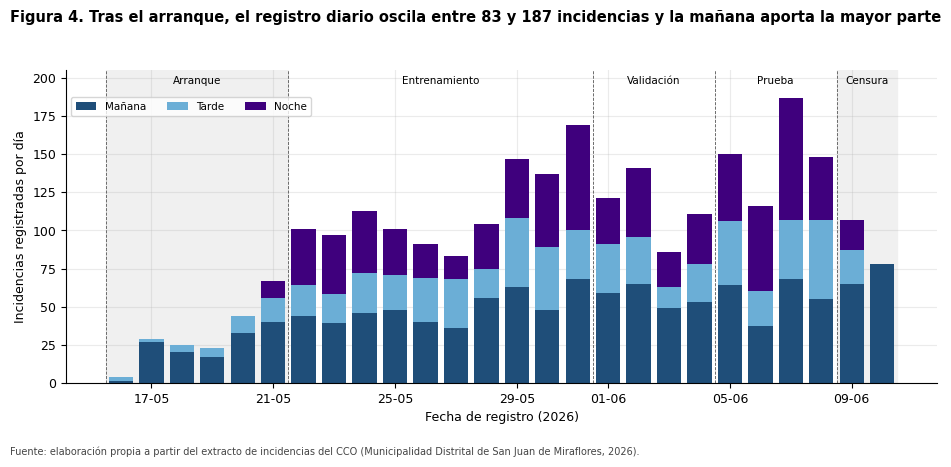

turno  Mañana  Tarde  Noche  total
count    14.0   14.0   14.0   14.0
mean     51.0   27.7   35.7  114.4
std      10.0    8.7   13.3   25.5
min      36.0   14.0   15.0   83.0
25%      44.5   20.8   29.2   98.0
50%      48.5   27.5   35.0  107.5
75%      58.2   32.0   40.5  133.0
max      68.0   45.0   69.0  169.0


In [2]:
serie = df.groupby(["fecha_dt", "turno"]).size().unstack(fill_value=0).reindex(columns=TURNOS)
serie = serie.reindex(pd.date_range(df.fecha_dt.min(), df.fecha_dt.max()), fill_value=0)
fig, ax = plt.subplots(figsize=(9.5, 4.6))
bottom = np.zeros(len(serie))
for t in TURNOS:
    ax.bar(serie.index, serie[t], bottom=bottom, color=COLOR_TURNO[t], label=t, width=0.8)
    bottom += serie[t].values
spans = [("2026-05-16", FIN_ARRANQUE, "Arranque", "#F0F0F0"),
         (*PARTICION["train"], "Entrenamiento", None), (*PARTICION["valid"], "Validación", None),
         (*PARTICION["test"], "Prueba", None), (FECHAS_CENSURADAS[0], FECHAS_CENSURADAS[-1], "Censura", "#F0F0F0")]
for i, f, txt, col in spans:
    a, b = pd.Timestamp(i) - pd.Timedelta(hours=12), pd.Timestamp(f) + pd.Timedelta(hours=12)
    if col:
        ax.axvspan(a, b, color=col, zorder=0)
    ax.axvline(a, color="#555555", lw=0.6, ls="--")
    ax.text(a + (b - a) / 2, 196, txt, ha="center", fontsize=7.5)
ax.set_ylim(0, 205); ax.set_ylabel("Incidencias registradas por día"); ax.set_xlabel("Fecha de registro (2026)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
ax.legend(loc="upper left", fontsize=7.5, ncol=3, bbox_to_anchor=(0, 0.93))
guardar_figura(fig, "fig04_serie_diaria_turno.png", 4,
               "Tras el arranque, el registro diario oscila entre 83 y 187 incidencias y la mañana aporta la mayor parte")
print(serie.assign(total=serie.sum(1)).loc["2026-05-22":"2026-06-04"].describe().round(1).to_string())
estable_dia = serie.loc[INI_EDA:FIN_EDA].sum(1)
metricas.update(dia_min=int(estable_dia.min()), dia_max=int(estable_dia.max()), dia_media=round(float(estable_dia.mean()), 1),
                dia_cv=round(float(estable_dia.std() / estable_dia.mean()), 3))

## 2. Distribución por turno

In [3]:
por_turno = eda.turno.value_counts().reindex(TURNOS)
tabla_turno = pd.DataFrame({"registros": por_turno, "pct": (por_turno / por_turno.sum() * 100).round(1),
                            "por_fecha_turno": (por_turno / n_dias_eda).round(1)})
print(tabla_turno.to_string())
metricas["turno"] = {t: {"registros": int(r.registros), "pct": float(r.pct), "media": float(r.por_fecha_turno)} for t, r in tabla_turno.iterrows()}

        registros   pct  por_fecha_turno
turno                                   
Mañana        714  44.6             51.0
Tarde         388  24.2             27.7
Noche         500  31.2             35.7


## 3. Día de la semana × turno
Con 14 días cada combinación día-turno se observa solo **2 veces**: el mapa de calor es descriptivo, no concluyente.

Repeticiones por día de la semana: {0: 2, 1: 2, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2}
turno  Mañana  Tarde  Noche
Lun      53.5   27.5   30.0
Mar      52.5   30.0   33.5
Mié      42.5   23.0   19.0
Jue      54.5   22.0   31.0
Vie      53.5   32.5   38.0
Sáb      43.5   30.0   43.5
Dom      57.0   29.0   55.0


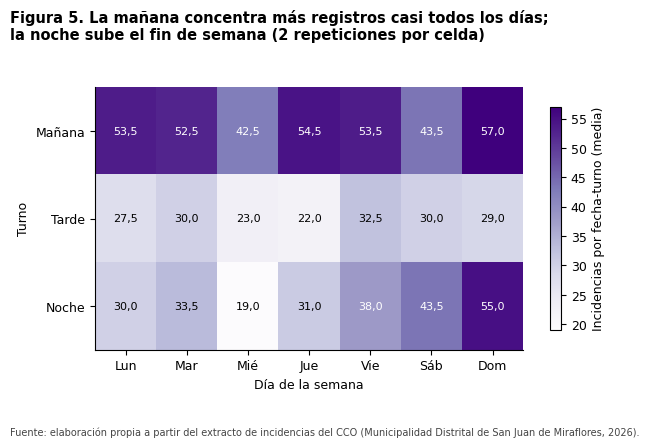

Media fin de semana: {'Mañana': 50.2, 'Tarde': 29.5, 'Noche': 49.2} · laborable: {'Mañana': 51.3, 'Tarde': 27.0, 'Noche': 30.3}


In [4]:
eda["dia_semana"] = eda.fecha_dt.dt.dayofweek
conteo_ft = eda.groupby(["fecha", "turno"]).size().unstack(fill_value=0).reindex(columns=TURNOS)
conteo_ft.index = pd.to_datetime(conteo_ft.index)
media_dt = conteo_ft.groupby(conteo_ft.index.dayofweek).mean()
media_dt.index = [DIAS[i] for i in media_dt.index]
repeticiones = conteo_ft.groupby(conteo_ft.index.dayofweek).size()
print("Repeticiones por día de la semana:", repeticiones.to_dict())
print(media_dt.round(1).to_string())
fig, ax = plt.subplots(figsize=(6.4, 4.4))
im = ax.imshow(media_dt.T.values, cmap="Purples", aspect="auto")
ax.set_xticks(range(7)); ax.set_xticklabels(media_dt.index)
ax.set_yticks(range(3)); ax.set_yticklabels(TURNOS)
for i in range(3):
    for j in range(7):
        v = media_dt.T.values[i, j]
        ax.text(j, i, fmt(v, 1), ha="center", va="center", fontsize=8, color="white" if v > media_dt.values.max() * 0.6 else "black")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.85); cb.set_label("Incidencias por fecha-turno (media)")
ax.set_xlabel("Día de la semana"); ax.set_ylabel("Turno")
guardar_figura(fig, "fig05_mapa_calor_dia_turno.png", 5,
               "La mañana concentra más registros casi todos los días;\nla noche sube el fin de semana (2 repeticiones por celda)")
finde = conteo_ft[conteo_ft.index.dayofweek >= 5].mean(); laboral = conteo_ft[conteo_ft.index.dayofweek < 5].mean()
print("Media fin de semana:", finde.round(1).to_dict(), "· laborable:", laboral.round(1).to_dict())
metricas["dia_turno"] = {d: {t: round(float(v), 1) for t, v in fila.items()} for d, fila in media_dt.iterrows()}
metricas["finde_vs_laboral"] = {"finde": finde.round(1).to_dict(), "laboral": laboral.round(1).to_dict()}

## 4. Hora del día

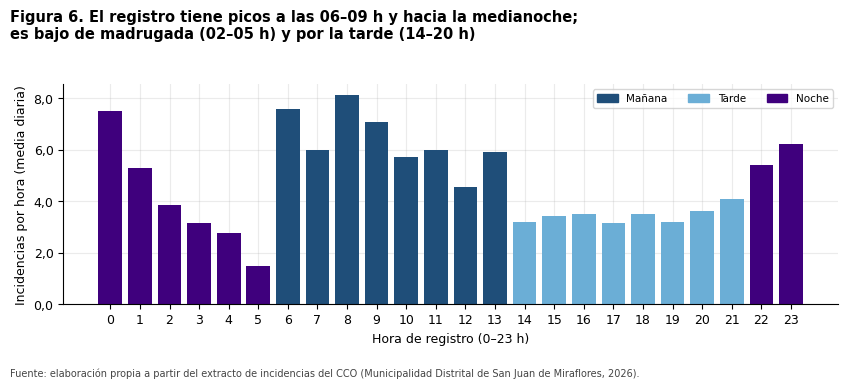

hora_num
0     7.50
1     5.29
2     3.86
3     3.14
4     2.79
5     1.50
6     7.57
7     6.00
8     8.14
9     7.07
10    5.71
11    6.00
12    4.57
13    5.93
14    3.21
15    3.43
16    3.50
17    3.14
18    3.50
19    3.21
20    3.64
21    4.07
22    5.43
23    6.21


In [5]:
por_hora = eda.hora_num.value_counts().reindex(range(24), fill_value=0) / n_dias_eda
fig, ax = plt.subplots(figsize=(8.5, 3.8))
colores = [COLOR_TURNO["Mañana"] if 6 <= h < 14 else COLOR_TURNO["Tarde"] if 14 <= h < 22 else COLOR_TURNO["Noche"] for h in range(24)]
ax.bar(range(24), por_hora.values, color=colores)
from matplotlib.patches import Patch
ax.set_xticks(range(24)); ax.set_xlabel("Hora de registro (0–23 h)"); ax.set_ylabel("Incidencias por hora (media diaria)")
eje_es(ax, "y", 1); ax.legend(handles=[Patch(color=COLOR_TURNO[t], label=t) for t in TURNOS], fontsize=7.5, ncol=3)
guardar_figura(fig, "fig06_hora_del_dia.png", 6,
               "El registro tiene picos a las 06–09 h y hacia la medianoche;\nes bajo de madrugada (02–05 h) y por la tarde (14–20 h)")
print(por_hora.round(2).to_string())
metricas["hora_pico"] = int(por_hora.idxmax()); metricas["hora_valle"] = int(por_hora.idxmin())
metricas["por_hora"] = {int(h): round(float(v), 2) for h, v in por_hora.items()}

## 5. Evolución por tipo (incluye el arranque como referencia)

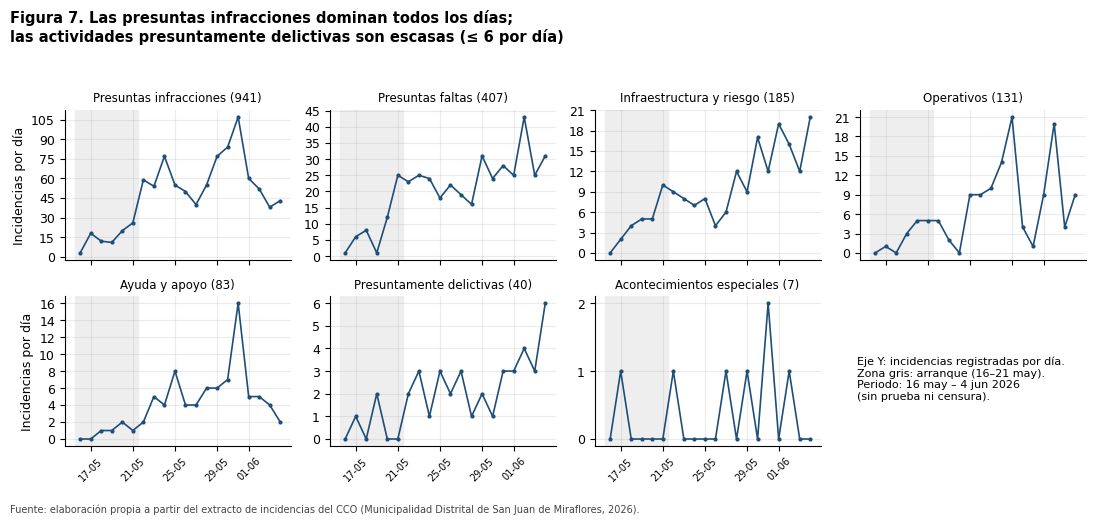

tipo_corto
Presuntas infracciones        53.1
Presuntas faltas              22.1
Infraestructura y riesgo       9.9
Operativos                     7.3
Ayuda y apoyo                  4.9
Presuntamente delictivas       2.3
Acontecimientos especiales     0.4


In [6]:
ev = df[(df.fecha <= FIN_EDA)].groupby(["fecha_dt", "tipo_corto"]).size().unstack(fill_value=0)
orden = ev.sum().sort_values(ascending=False).index
fig, axes = plt.subplots(2, 4, figsize=(11, 5.2), sharex=True)
for ax, tipo in zip(axes.flat, orden):
    ax.plot(ev.index, ev[tipo], color=AZUL, lw=1.2, marker="o", ms=2)
    ax.axvspan(pd.Timestamp("2026-05-15 12:00"), pd.Timestamp(FIN_ARRANQUE + " 12:00"), color="#EEEEEE", zorder=0)
    ax.set_title(f"{tipo} ({fmt(ev[tipo].sum())})", fontsize=8.5)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m")); ax.tick_params(axis="x", labelsize=7, rotation=45)
axes.flat[-1].set_visible(False)
fig.text(0.78, 0.27, "Eje Y: incidencias registradas por día.\nZona gris: arranque (16–21 may).\nPeriodo: 16 may – 4 jun 2026\n(sin prueba ni censura).", fontsize=8, va="center")
from matplotlib.ticker import MaxNLocator
for ax in axes.flat[:-1]:
    ax.yaxis.set_major_locator(MaxNLocator(integer=True)); eje_es(ax, "y", 0)
for ax in axes[:, 0]:
    ax.set_ylabel("Incidencias por día")
max_del = int(ev["Presuntamente delictivas"].max())
guardar_figura(fig, "fig07_evolucion_tipo.png", 7,
               f"Las presuntas infracciones dominan todos los días;\nlas actividades presuntamente delictivas son escasas (≤ {max_del} por día)")
comp = eda.tipo_corto.value_counts()
print((comp / comp.sum() * 100).round(1).to_string())
metricas["tipo_pct_eda"] = {k: round(float(v), 1) for k, v in (comp / comp.sum() * 100).items()}
metricas["delictivas_max_dia"] = int(ev.get("Presuntamente delictivas", pd.Series([0])).max())

## 6. Autocorrelación simple para orientar los rezagos
**Distrito:** autocorrelación del total diario (rezagos 1–7). **Celda:** con una grilla provisional de 500 m (la elección formal está en
`03_espacial`), correlación de Spearman entre el conteo de una celda-fecha-turno y (a) el total de la celda el día anterior,
(b) el mismo turno del día anterior y (c) el mismo turno 7 días antes. Las fechas objetivo son 29 may – 4 jun para que el rezago de 7 días
caiga dentro de la ventana estable; se incluyen solo celdas con ≥ 1 registro en la ventana.

ACF del total diario (n = 14): {1: 0.379, 2: 0.352, 3: -0.278, 4: -0.254, 5: -0.428, 6: -0.281, 7: 0.69}
Celdas: 89 · observaciones objetivo: 1869
Spearman: {'lag1_celda': 0.335, 'lag1_turno': 0.271, 'lag7_turno': 0.242} 
Pearson: {'lag1_celda': 0.42, 'lag1_turno': 0.374, 'lag7_turno': 0.262}


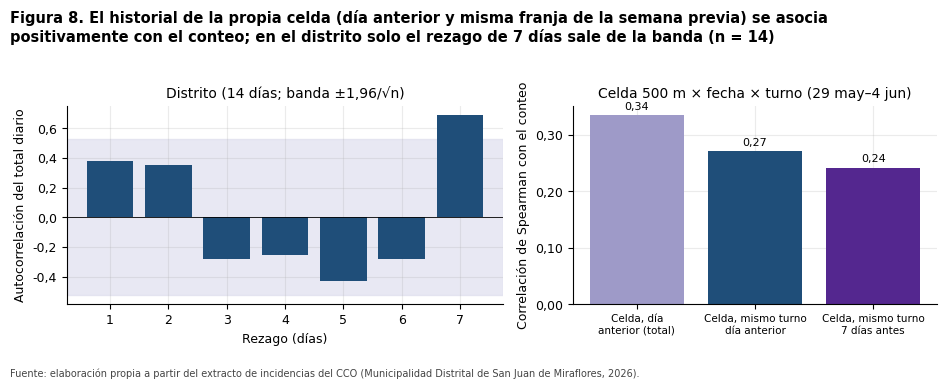

2353

In [7]:
total = serie.sum(1).loc[INI_EDA:FIN_EDA]
acf = {k: round(float(total.autocorr(lag=k)), 3) for k in range(1, 8)}
print("ACF del total diario (n = 14):", acf)
TAM = 500
org = origen_grilla(TAM)
df["col"], df["fila"] = celda_de(df.x_utm, df.y_utm, TAM, org)
ventana = df[(df.fecha >= INI_EDA) & (df.fecha <= FIN_EDA)]
celdas = sorted(set(zip(ventana.col, ventana.fila)))
fechas = fechas_rango(INI_EDA, FIN_EDA)
idx = pd.MultiIndex.from_product([celdas, fechas, TURNOS], names=["celda", "fecha", "turno"])
ventana = ventana.assign(celda=list(zip(ventana.col, ventana.fila)))
cnt = ventana.groupby(["celda", "fecha", "turno"]).size().reindex(idx, fill_value=0).rename("y").reset_index()
cnt["fecha_dt"] = pd.to_datetime(cnt.fecha)
piv = cnt.set_index(["celda", "turno", "fecha_dt"]).y
def desplazar(dias):
    s = cnt.copy(); s["fecha_dt"] = s.fecha_dt + pd.Timedelta(days=dias)
    return s.set_index(["celda", "turno", "fecha_dt"]).y
tot_celda = cnt.groupby(["celda", "fecha_dt"]).y.sum()
obj = cnt[(cnt.fecha >= "2026-05-29") & (cnt.fecha <= FIN_EDA)].copy()
k = list(zip(obj.celda, obj.turno, obj.fecha_dt))
obj["lag1_turno"] = desplazar(1).reindex(k).values
obj["lag7_turno"] = desplazar(7).reindex(k).values
tc = tot_celda.reset_index(); tc["fecha_dt"] = tc.fecha_dt + pd.Timedelta(days=1)
obj["lag1_celda"] = tc.set_index(["celda", "fecha_dt"]).y.reindex(list(zip(obj.celda, obj.fecha_dt))).values
corr = {c: round(float(obj[["y", c]].corr(method="spearman").iloc[0, 1]), 3) for c in ["lag1_celda", "lag1_turno", "lag7_turno"]}
corr_p = {c: round(float(obj[["y", c]].corr().iloc[0, 1]), 3) for c in ["lag1_celda", "lag1_turno", "lag7_turno"]}
print(f"Celdas: {len(celdas)} · observaciones objetivo: {len(obj)}")
print("Spearman:", corr, "\nPearson:", corr_p)
metricas.update(acf_distrito=acf, corr_celda_spearman=corr, corr_celda_pearson=corr_p, n_obs_corr=int(len(obj)), n_celdas_corr=len(celdas))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
a1.bar(list(acf.keys()), list(acf.values()), color=AZUL)
a1.axhline(0, color="k", lw=0.6)
lim = 1.96 / np.sqrt(len(total)); a1.axhspan(-lim, lim, color="#DADAEB", alpha=0.6, zorder=0)
a1.set_xlabel("Rezago (días)"); a1.set_ylabel("Autocorrelación del total diario"); a1.set_title("Distrito (14 días; banda ±1,96/√n)")
eje_es(a1, "y", 1)
etiquetas = {"lag1_celda": "Celda, día\nanterior (total)", "lag1_turno": "Celda, mismo turno\ndía anterior", "lag7_turno": "Celda, mismo turno\n7 días antes"}
a2.bar([etiquetas[c] for c in corr], list(corr.values()), color=["#9E9AC8", AZUL, "#54278F"])
for i, v in enumerate(corr.values()):
    a2.text(i, v + 0.01, fmt(v, 2), ha="center", fontsize=8)
a2.set_ylabel("Correlación de Spearman con el conteo"); a2.set_title("Celda 500 m × fecha × turno (29 may–4 jun)")
a2.tick_params(axis="x", labelsize=7.5); eje_es(a2, "y", 2)
guardar_figura(fig, "fig08_autocorrelacion.png", 8,
               "El historial de la propia celda (día anterior y misma franja de la semana previa) se asocia\npositivamente con el conteo; en el distrito solo el rezago de 7 días sale de la banda (n = 14)")
(DATOS / "metricas_temporal.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")

## Hallazgos

Ver las cifras exactas en las salidas y en `datos/metricas_temporal.json` (ventana 22 may – 4 jun, sin prueba).

1. **Nivel diario.** Tras el arranque, el registro diario es variable (83 a 169 por día entre el 22 may y el 4 jun; coeficiente de variación 0,22) y con tendencia creciente
   asociada al cambio de cobertura (ver `01_calidad`).
2. **Turno.** Mañana 44,6 %, noche 31,2 % y tarde 24,2 % (22 may–4 jun); el turno es un predictor de calendario relevante.
3. **Día × turno.** La noche sube el fin de semana (49,2 frente a 30,3 registros por turno en días laborables), pero cada combinación tiene solo 2 repeticiones: el efecto del día de la semana es
   **exploratorio**. Hay un único feriado en el periodo (7 jun, domingo, en prueba), por lo que su efecto no puede estimarse.
4. **Hora.** Picos a las 06–09 h (máximo a las 08 h, 8,1 por hora) y hacia la medianoche; valles de madrugada (05 h, 1,5) y por la tarde (14–20 h, ~3,3). El patrón horario coincide con los turnos del CCO
   y con la operación de cámaras, lo que refuerza que se mide el **esfuerzo de registro** además de la ocurrencia.
5. **Tipo.** Las presuntas infracciones dominan (53,1 %), seguidas de las presuntas faltas (22,1 %); las actividades presuntamente delictivas son raras, por lo que no se modelan por separado.
6. **Autocorrelación.** En la celda (500 m), el conteo se correlaciona positivamente con el total de la celda el día anterior (Spearman 0,34),
   con el mismo turno del día anterior (0,27) y con la misma fecha-turno de la semana previa (0,24): correlaciones modestas pero consistentes
   que justifican los rezagos de 1 y 7 días y los acumulados móviles. En el distrito, el único rezago fuera de la banda de ±1,96/√n es el de
   7 días (0,69), un indicio de ciclo semanal que, con 14 puntos, debe tomarse como exploratorio.